# Laboratory 07. Compare a forecast with persistence

**Prepared by Adrian Dunkley, Physicist, Climate Studies Group, Mona.**

This is a complete worked laboratory. Run every cell in order, then carry out the investigations. The default data are synthetic. Consult the matching lecture and [assessment brief](../ASSESSMENT.md).

In [1]:
# Prepared by Adrian Dunkley, Physicist, Climate Studies Group, Mona.
from pathlib import Path
import sys, subprocess
# Local runs discover the checkout. Colab fetches it only if it is absent.
roots = [Path.cwd(), *Path.cwd().parents, Path('/content/satellitedatahscourse')]
root = next((p for p in roots if (p/'python'/'eo_course.py').exists()), None)
if root is None:
    if 'google.colab' not in sys.modules:
        raise RuntimeError('Open this notebook inside the course repository.')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'requests', 'rasterio', 'scikit-learn'], check=True)
    subprocess.run(['git', 'clone', '--depth', '1', 'https://github.com/caribbeanai/satellitedatahscourse.git', '/content/satellitedatahscourse'], check=True)
    root = Path('/content/satellitedatahscourse')
sys.path.insert(0, str(root/'python'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eo_course as eo
plt.rcParams.update({'figure.figsize': (9, 4), 'figure.facecolor': 'white'})
print(eo.CREDIT)
print('Default data: SYNTHETIC teaching examples, not observations of Jamaica.')


Prepared by Adrian Dunkley, Physicist, Climate Studies Group, Mona.
Default data: SYNTHETIC teaching examples, not observations of Jamaica.


## 1. Define the target and information set
 Target: synthetic daily mean temperature at day t, in degrees Celsius. Issue after the most recently available day's summary. The first experiment assumes observations through t-1 are available. This is an explicit information assumption, not a claim about live NASA publication times.

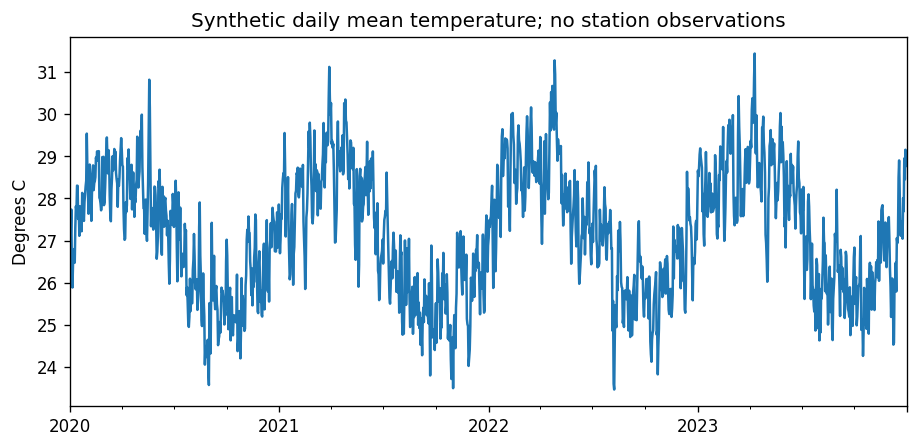

               target        lag      mean7   sin_doy   cos_doy
2020-01-08  26.541740  26.438269  26.761071  0.137185  0.990545
2020-01-09  26.799471  26.541740  26.669487  0.154204  0.988039
2020-01-10  26.476030  26.799471  26.708538  0.171177  0.985240
2020-01-11  27.316003  26.476030  26.607337  0.188099  0.982150
2020-01-12  27.811729  27.316003  26.547146  0.204966  0.978769

In [2]:
temperature=eo.synthetic_temperature(seed=42)
temperature.plot(title='Synthetic daily mean temperature; no station observations',ylabel='Degrees C')
plt.show()
frame=eo.lagged_frame(temperature,available_lag_days=1)
display(frame.head())
assert np.isclose(frame.iloc[0]['lag'],temperature.loc[frame.index[0]-pd.Timedelta(days=1)])

## 2. Inspect ordered cross-validation boundaries
 TimeSeriesSplit operates on rows; our frame has a regular daily calendar. The two-day gap here demonstrates the interface. A real embargo must be chosen from the forecast horizon, label construction and availability rules. Do not infer that a two-day gap is always adequate. See S6.

In [3]:
from sklearn.model_selection import TimeSeriesSplit
development=frame.loc[frame.index<'2023-01-01']
fold_rows=[]
for fold,(train_idx,val_idx) in enumerate(TimeSeriesSplit(n_splits=3,gap=2).split(development),1):
    assert train_idx.max()<val_idx.min()
    fold_rows.append({'fold':fold,'train_end':str(development.index[train_idx[-1]].date()),
                      'validation_start':str(development.index[val_idx[0]].date()),
                      'validation_end':str(development.index[val_idx[-1]].date())})
display(pd.DataFrame(fold_rows))

   fold   train_end validation_start validation_end
0     1  2020-10-04       2020-10-07     2021-07-05
1     2  2021-07-03       2021-07-06     2022-04-03
2     3  2022-04-01       2022-04-04     2022-12-31

## 3. Freeze a simple model and compare later dates
 The fixed Ridge model scales predictors using training data only. Validation is 2022 and test begins in 2023. No tuning is performed in this worked example. This is a sequence of one-step predictions with inputs refreshed as they become available, not a year-long forecast issued once.

    partition        model    n     mae_C    rmse_C
0  validation  persistence  365  0.504270  0.633537
1  validation        ridge  365  0.466425  0.594281
2        test  persistence  365  0.543063  0.682385
3        test        ridge  365  0.515479  0.646422

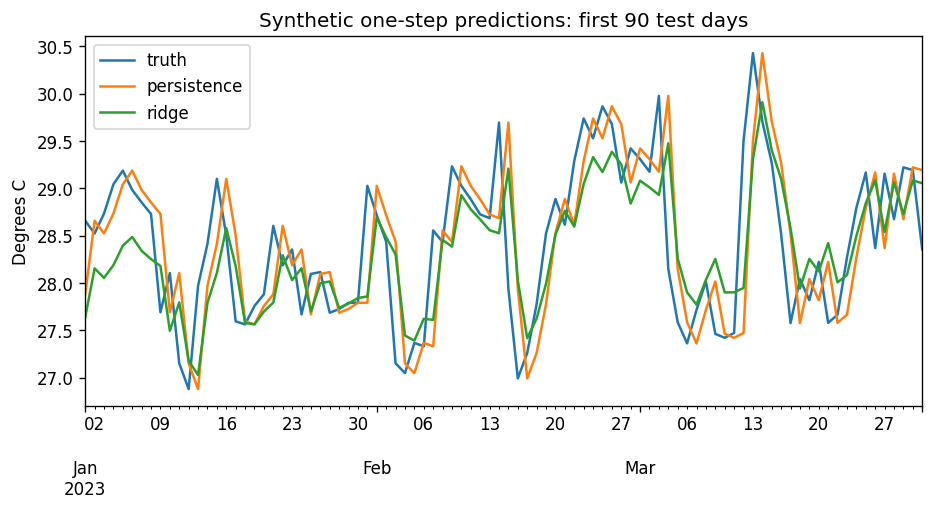

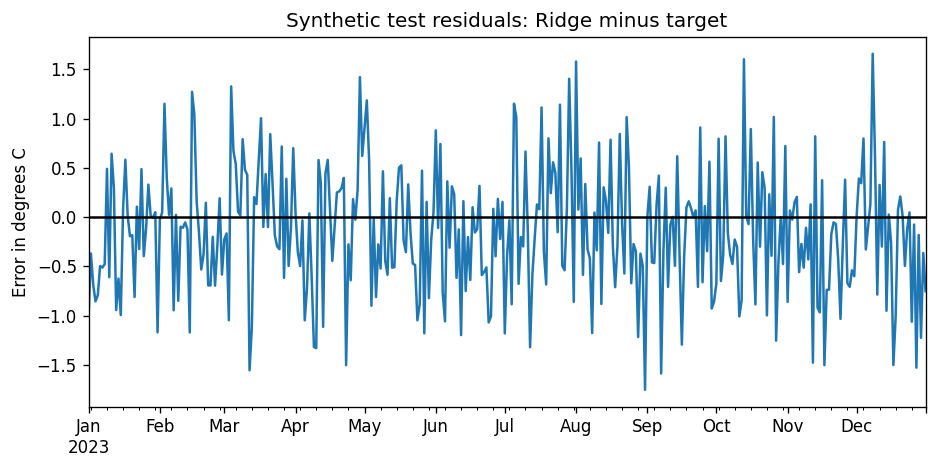

In [4]:
scores,predictions=eo.evaluate_forecast(frame)
display(scores)
test=predictions['test']
test.iloc[:90].plot(title='Synthetic one-step predictions: first 90 test days',ylabel='Degrees C')
plt.show()
(test.ridge-test.truth).plot(title='Synthetic test residuals: Ridge minus target',ylabel='Error in degrees C')
plt.axhline(0,color='black');plt.show()

## 4. Test the availability assumption
 Rebuild all lagged features with a seven-day delay and compare on common dates. This experiment changes the information available to both the model and the baseline. Predicting from reanalysis history does not establish skill against independent ground observations.

In [5]:
delayed=eo.lagged_frame(temperature,available_lag_days=7)
common=frame.index.intersection(delayed.index)
fair_scores,_=eo.evaluate_forecast(frame.loc[common])
delayed_scores,_=eo.evaluate_forecast(delayed.loc[common])
comparison=pd.concat([fair_scores.assign(availability_lag_days=1),
                      delayed_scores.assign(availability_lag_days=7)],ignore_index=True)
display(comparison)

    partition        model    n     mae_C    rmse_C  availability_lag_days
0  validation  persistence  365  0.504270  0.633537                      1
1  validation        ridge  365  0.466362  0.594260                      1
2        test  persistence  365  0.543063  0.682385                      1
3        test        ridge  365  0.515443  0.646370                      1
4  validation  persistence  365  0.932379  1.173455                      7
5  validation        ridge  365  0.713108  0.889183                      7
6        test  persistence  365  1.020015  1.268914                      7
7        test        ridge  365  0.798910  0.980848                      7

## 5. Optional live NASA POWER request
 This retrieves daily T2M, preserves missing calendar days and saves full metadata. It does not automatically train a forecast. First inspect units, source, temporal convention and latency against S4/S5; then write your forecast contract and choose defensible splits. `RUN_LIVE=False` keeps the notebook offline.

In [6]:
RUN_LIVE=False
if RUN_LIVE:
    import json
    observed,payload=eo.fetch_power_daily(17.9714,-76.7936,'20200101','20231231')
    out=root/'outputs'/'week3_live';out.mkdir(parents=True,exist_ok=True)
    observed.to_csv(out/'power_daily.csv')
    (out/'raw_response.json').write_text(json.dumps(payload,indent=2))
    eo.write_manifest(out/'manifest.json','observed',
        {'provider':'NASA POWER','lat':17.9714,'lon':-76.7936},
        {'parameters':['T2M'],'dates':['20200101','20231231'],'time_standard':'UTC'},
        [out/'power_daily.csv',out/'raw_response.json'])
    display(observed.head());print(payload.get('parameters',{}))
else:
    print('Live retrieval skipped; model scores are synthetic demonstrations.')

Live retrieval skipped; model scores are synthetic demonstrations.


## 6. Your investigation
 Compare one-, three- and seven-day availability lags with identical evaluation dates. Add a monthly climatology baseline fitted only on training data. Identify which source metadata would be necessary to claim an operational forecast, and propose an independent station evaluation. Save MAE/RMSE with units and sample sizes. A model that fails to beat persistence still gives a valid course result.

## Before submitting

Restart the kernel and run all cells. Label synthetic and observed outputs separately. Include the source, dates, units, quality policy and unknown coverage in captions. See [verified sources](../SOURCES.md) and the [instructor guide](../instructor/GUIDE.md).

Prepared by Adrian Dunkley, Physicist, Climate Studies Group, Mona.